# Career Value of NFL Combine Outliers Relative to Draft Position

Santiago Criado, Phu Duong, Sri Indla, and Steven Goetz

COS 424: Reasoning with Data · Princeton University

We study whether NFL teams draft prospects with unusual physical and athletic profiles more often or earlier than typical prospects. We also ask whether those players produce more career value than expected for their draft pick, position, and draft class.

We begin by identifying favorable athletic outliers, unfavorable outliers, and unusual builds within each position.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

from utils import detect, features, plots, prepare, summaries

plots.use_style()

## 1. Data and sample

We use an October 2026 snapshot of the Combine, Draft Picks, and Players tables from [nflverse](https://github.com/nflverse/nflverse-data). The notebook verifies each file's SHA-256 checksum before loading it.

| Table | Information used |
| --- | --- |
| Combine | Height, weight, six workout results, and draft information for prospects from 2000 to 2026 |
| Draft Picks | Draft year, overall pick, round, position, and career Weighted Approximate Value (WAV) |
| Players | NFL roster positions used to refine broad Combine labels |

In [2]:
prepare.verify_snapshot()
raw = prepare.load_raw()
display(summaries.raw_overview(raw))

,rows,columns
combine,8968,18
draft_picks,12927,36
players,24844,39


### Sample construction

We link the Combine and Draft Picks tables by draft year and overall pick. The 2026 Combine records lack draft slots in our snapshot, so we first match that class to the draft table by exact player name. When multiple Combine records share a pick, we give preference to the record whose position family matches the draft record.

We use 11 position groups. For broad offensive line, defensive line, and defensive back labels, we use roster or draft position where it resolves the label and measured size otherwise. We group outside linebackers by weight. We convert height to inches, require recorded height, weight, and 40-yard dash time, and exclude records outside the weight bounds for their assigned position.

In [3]:
sample = prepare.build_sample(raw)
prospects = sample.prospects

print(f"{prepare.UNLINKED_CLASS} draft slots linked by name: {sample.linked_by_name:,}")
display(sample.log)

2026 draft slots linked by name: 211


,Step,Rows remaining,Removed
0,"Combine records, 2000–2026",8968,0
1,Drop namesakes sharing one draft pick,8958,10
2,Keep the 11 position groups,8528,430
3,"Require height, weight and 40 time",7699,829
4,Remove sizes impossible for the position,7690,9


### Sample characteristics

Weight and 40-yard dash time vary across positions. The scatterplot shows both measurements for the cleaned sample, and the heatmap shows the fraction of drill results missing for each position after applying the sample restrictions.

,prospects,drafted,mean_ht,mean_wt,mean_forty,mean_drills
grp,,,,,,
QB,413,239,74.69,222.18,4.81,4.35
RB,716,424,70.42,213.12,4.55,4.47
WR,1156,708,72.74,201.01,4.51,4.36
TE,452,299,76.29,252.95,4.76,4.74
OT,608,440,77.64,315.40,5.23,4.76
IOL,722,433,75.82,311.02,5.26,4.86
DT,604,431,74.96,306.74,5.09,4.59
EDGE,826,604,75.52,263.24,4.78,4.66
LB,718,483,73.41,237.12,4.69,4.63


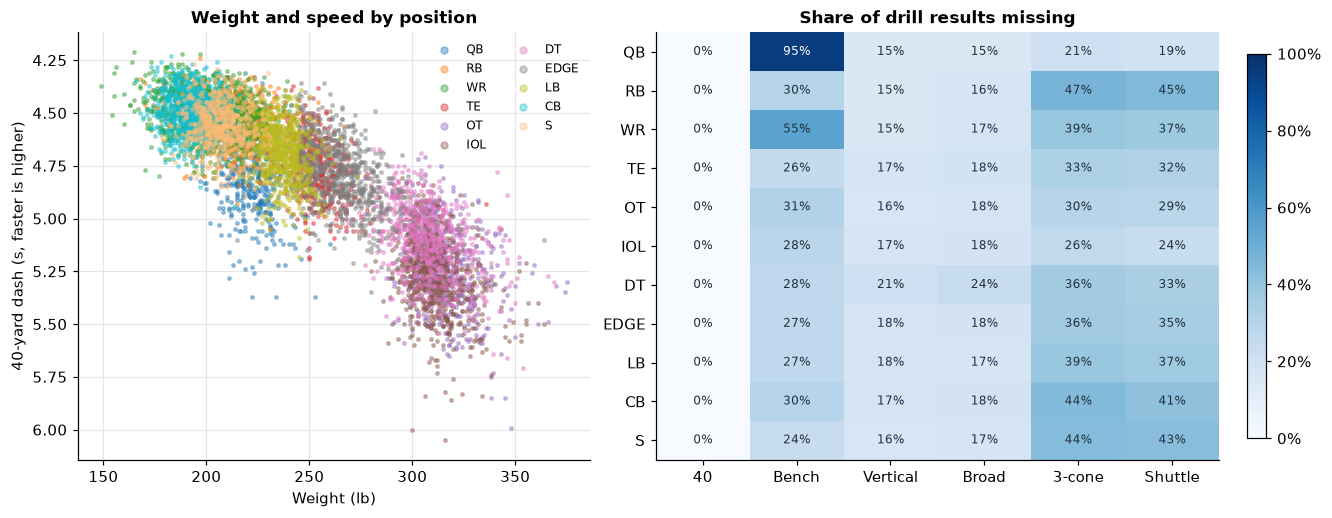

7,690 prospects, of whom 5,081 were drafted. 23.7% of drill results are missing.


In [4]:
display(summaries.sample_census(prospects).round(2))
missing_drills = summaries.drill_missing_by_position(prospects)
plots.sample_overview(prospects, missing_drills)
plt.show()
print(
    f"{len(prospects):,} prospects, of whom {prospects['drafted'].sum():,} were drafted. "
    f"{prospects[prepare.DRILLS].isna().to_numpy().mean():.1%} of drill results are missing."
)

## 2. Adjustment for size and era

Within each position, we regress each drill result on height, weight, squared weight, Combine year, and an indicator for the 2021 pro-day class. We fit each regression using the players with a recorded result for that drill. We then center the residuals at the median measured residual and scale them by 1.4826 times their median absolute deviation. We reverse the sign for timed drills so that better performances receive higher scores. We also scale height and weight within each position for the distance calculation.

The full-workout score includes drills recorded for at least 25% of prospects in a position group. We use iterative imputation to estimate missing results for those drills from height, weight, and the other drills, then apply the same regression adjustment. Imputed results can affect the rankings.

We average the adjusted drill scores and standardize that average within position to obtain the athleticism score.

In [5]:
with threadpool_limits(limits=1):
    adjusted = features.adjust_drills(prospects)

display(summaries.fastest_for_size(adjusted).round(2))

,player_name,season,grp,ht,wt,forty,z_ht,z_wt,adj_forty,adj_vertical,ath_z
3091,Bruce Campbell,2010,OT,78.0,314.0,4.75,0.00,0.10,3.20,1.22,1.79
1874,Vernon Davis,2006,TE,75.0,254.0,4.38,-0.67,0.22,3.16,2.87,3.45
3986,Terron Armstead,2013,OT,77.0,306.0,4.71,-0.67,-0.67,3.03,1.90,1.98
6673,Jordan Davis,2022,DT,78.0,341.0,4.78,2.02,2.62,2.96,1.73,3.08
851,Donte' Stallworth,2002,WR,72.0,197.0,4.22,-0.34,-0.25,2.94,0.97,1.86
1543,Elton Brown,2005,IOL,77.0,329.0,4.93,0.67,1.93,2.94,0.87,2.19
4105,Lane Johnson,2013,OT,78.0,303.0,4.72,0.00,-0.96,2.89,1.59,2.37
6501,Jayson Oweh,2021,EDGE,77.0,257.0,4.36,1.35,-0.34,2.88,1.97,2.70


## 3. Outlier detection

We use robust Mahalanobis distance to identify players with unusual combinations of physical measurements and drill results. The distance accounts for correlations among the measurements. We estimate the center $\boldsymbol{\mu}$ and covariance $\boldsymbol{\Sigma}$ of each position group with the Minimum Covariance Determinant estimator. The initial fit uses approximately 85% of the group to limit the influence of extreme observations.

$$D^2(\mathbf{x}) = (\mathbf{x}-\boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$$

We calculate two distances for each player. The size-and-speed score uses height, weight, and adjusted 40-yard dash time, all based on recorded measurements. The full-workout score also uses the other eligible adjusted drills. We convert each distance to a percentile within position, retain the higher of the two percentiles, and rank those scores again within position. We flag players with a final rank above the 95th percentile. Ties receive their average rank, so the flagged share can differ slightly from 5%.

Among the flagged players, we classify those at least 0.75 standard deviations above the mean athleticism score for their position as favorable athletic outliers and those at least 0.75 standard deviations below the mean as unfavorable outliers. The remaining flagged players form the unusual-build group. Players outside the cutoff form the typical comparison group.

The distance uses physical measurements and adjusted drill scores. For some broad Combine labels, position assignment uses draft or roster information.

In [6]:
with threadpool_limits(limits=1):
    scored = detect.score_prospects(adjusted)

display(summaries.unicorn_counts(scored).rename(columns=plots.TYPE_LABEL))
print(f"{scored['unicorn'].sum():,} prospects flagged across all positions.")

utype,Favorable outlier,Unusual build,Unfavorable outlier,Typical
grp,,,,
QB,7,7,7,392
RB,5,14,18,679
WR,19,22,17,1098
TE,4,11,8,429
OT,6,13,12,577
IOL,9,14,13,686
DT,10,14,6,574
EDGE,14,14,13,785
LB,7,14,15,682


388 prospects flagged across all positions.


### Distribution of outlier scores

We compare the squared full-workout distances with the chi-square reference for a multivariate normal model. The upper tail of the observed distances exceeds this reference in all three positions shown. The horizontal line marks the 95th percentile of the full-workout distances for each position. The outlier cutoff uses the combined ranking from the full-workout and size-and-speed scores.

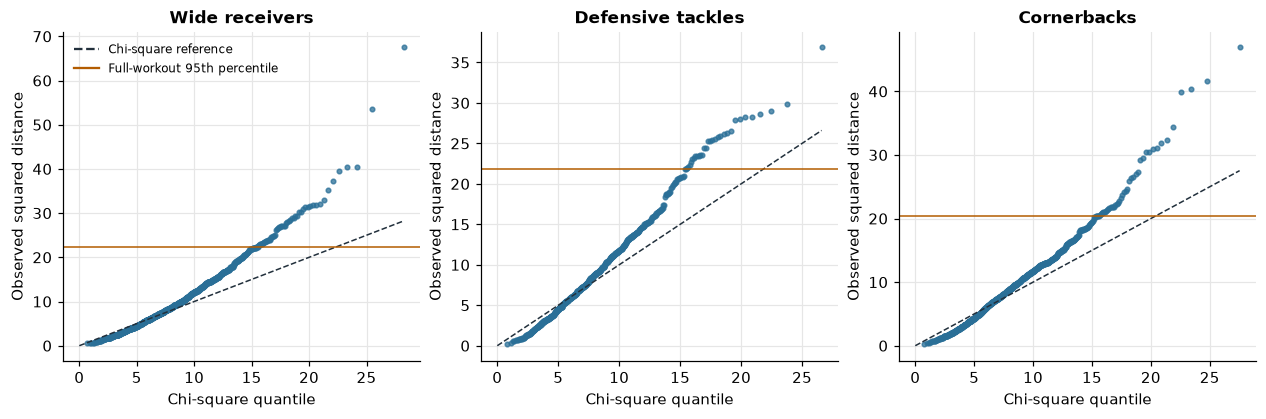

9.2% of prospects exceed the nominal 97.5th percentile in the full-workout view.


In [7]:
plots.chi2_qq(scored)
plt.show()
share_beyond_reference = summaries.share_beyond_chi2(scored)
print(
    f"{share_beyond_reference:.1%} of prospects exceed the nominal 97.5th percentile "
    "in the full-workout view."
)

### Outliers by position

The panels show weight and recorded 40-yard dash time for wide receivers, edge rushers, and cornerbacks. Faster times appear higher on the vertical axis. A player's weight and sprint time can look typical in the figure while the full profile is unusual. The distances use additional measurements and adjust drill results for size and era. Two of the highest-ranked outliers in each panel are labeled.

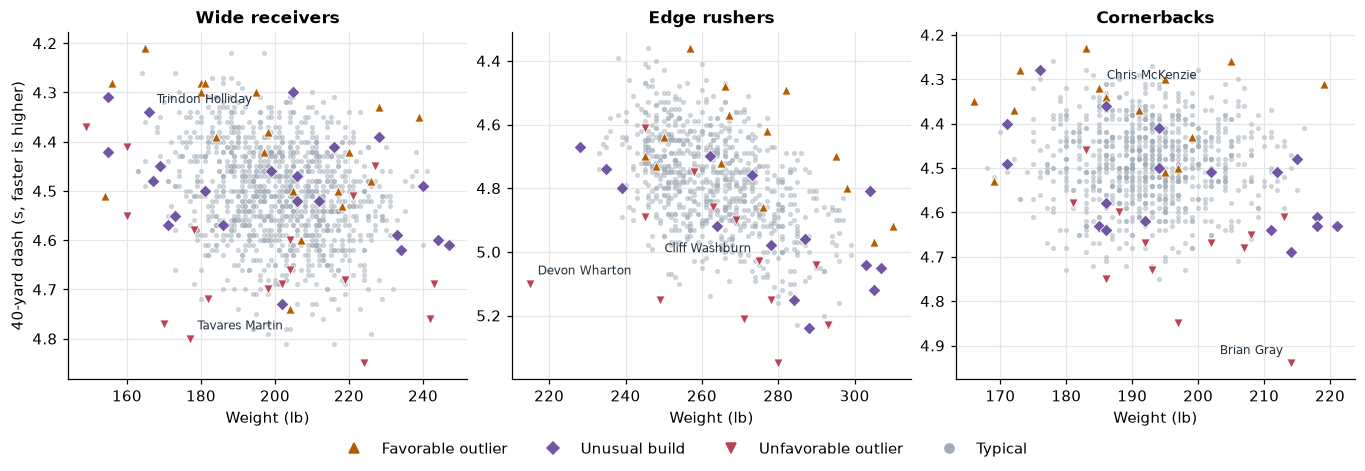

In [8]:
plots.unicorn_scatter(scored)
plt.show()